# 01 · LLM serving maths: will the model fit, how many users, how fast?

**Goal:** do GPU memory and throughput estimates on a whiteboard, the way you did for production serving.
**Time:** ~2 hours.

**Three formulas to memorise**
1. **Weights** ≈ total parameters × bytes per parameter (FP16/BF16 = 2, FP8 = 1, INT4 ≈ 0.5).
2. **KV cache per token** = 2 (K and V) × layers × KV heads × head dim × bytes.
3. **Decode speed upper bound** (batch 1) ≈ memory bandwidth ÷ bytes read per token (≈ active weights).
   Decoding is memory-bound; batching many users raises total throughput almost for free until compute or KV memory runs out.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

GB = 1e9
BYTES = {"fp16": 2, "bf16": 2, "fp8": 1, "int8": 1, "int4": 0.5}

# Public configs (from each model's config.json on Hugging Face)
MODELS = {
    "Llama-3.1-8B":   dict(params=8.0e9,  active=8.0e9,  layers=32, kv_heads=8, head_dim=128),
    "Qwen2.5-7B":     dict(params=7.6e9,  active=7.6e9,  layers=28, kv_heads=4, head_dim=128),
    "Llama-3.1-70B":  dict(params=70.6e9, active=70.6e9, layers=80, kv_heads=8, head_dim=128),
    "Mixtral-8x7B (MoE)": dict(params=46.7e9, active=12.9e9, layers=32, kv_heads=8, head_dim=128),
}
# Check the vendor spec sheet before quoting these in an interview
GPUS = {"T4": dict(mem=16, bw=320), "A100-80GB": dict(mem=80, bw=2039),
        "H100-SXM": dict(mem=80, bw=3350), "RTX PRO 6000 Blackwell": dict(mem=96, bw=1792)}

In [2]:
def weights_gb(m, dtype="bf16"):
    return m["params"] * BYTES[dtype] / GB

def kv_bytes_per_token(m, kv_dtype="bf16"):
    return 2 * m["layers"] * m["kv_heads"] * m["head_dim"] * BYTES[kv_dtype]

def plan(name, gpu="RTX PRO 6000 Blackwell", n_gpus=1, dtype="bf16", kv_dtype="bf16",
         ctx=8192, util=0.90, overhead_gb=2.0):
    m, g = MODELS[name], GPUS[gpu]
    usable = n_gpus * (g["mem"] * util - overhead_gb)     # vLLM reserves gpu_memory_utilization
    w = weights_gb(m, dtype)
    kv_free = usable - w
    tok_capacity = max(kv_free, 0) * GB / kv_bytes_per_token(m, kv_dtype)
    decode_tps = n_gpus * g["bw"] * GB / (m["active"] * BYTES[dtype])   # ideal TP scaling, batch 1
    return {"model": name, "GPUs": f"{n_gpus}x {gpu}", "dtype": dtype, "weights GB": round(w, 1),
            "KV MB/token": round(kv_bytes_per_token(m, kv_dtype) / 1e6, 3),
            "fits?": kv_free > 0, "KV tokens that fit": int(tok_capacity),
            f"full {ctx}-token seqs at once": int(tok_capacity // ctx),
            "decode tok/s ceiling (batch 1)": int(decode_tps)}

pd.DataFrame([
    plan("Llama-3.1-8B"),
    plan("Llama-3.1-8B", gpu="T4", dtype="int4", kv_dtype="fp16"),
    plan("Llama-3.1-70B"),
    plan("Llama-3.1-70B", n_gpus=2),
    plan("Llama-3.1-70B", dtype="fp8", kv_dtype="fp8"),
    plan("Mixtral-8x7B (MoE)"),
])

,model,GPUs,dtype,weights GB,KV MB/token,fits?,KV tokens that fit,full 8192-token seqs at once,decode tok/s ceiling (batch 1)
0,Llama-3.1-8B,1x RTX PRO 6000 Blackwell,bf16,16.0,0.131,True,521850,63,112
1,Llama-3.1-8B,1x T4,int4,4.0,0.131,True,64086,7,80
2,Llama-3.1-70B,1x RTX PRO 6000 Blackwell,bf16,141.2,0.328,False,0,0,12
3,Llama-3.1-70B,2x RTX PRO 6000 Blackwell,bf16,141.2,0.328,True,84228,10,25
4,Llama-3.1-70B,1x RTX PRO 6000 Blackwell,fp8,70.6,0.164,True,84228,10,25
5,Mixtral-8x7B (MoE),1x RTX PRO 6000 Blackwell,bf16,93.4,0.131,False,0,0,69


**Read the table:**
- 70B in BF16 needs ~141 GB of weights: it does not fit on one 96 GB GPU, but fits on 2 with tensor parallelism, or on 1 in FP8.
- MoE: memory is set by **total** parameters (all experts are loaded); speed by **active** parameters.

## How many concurrent users?
Users × average tokens in context must fit in KV memory. Plot it.

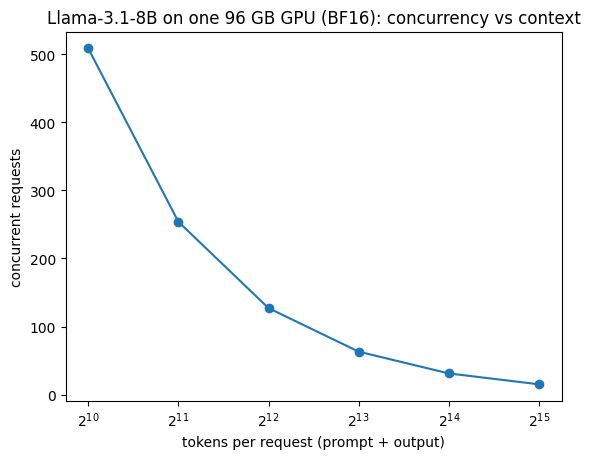

In [3]:
cfg = plan("Llama-3.1-8B")
ctx = [1024, 2048, 4096, 8192, 16384, 32768]
plt.plot(ctx, [cfg["KV tokens that fit"] // c for c in ctx], "o-")
plt.xscale("log", base=2); plt.xlabel("tokens per request (prompt + output)"); plt.ylabel("concurrent requests")
plt.title("Llama-3.1-8B on one 96 GB GPU (BF16): concurrency vs context"); plt.show()

## Tensor vs pipeline parallelism (you will be asked)
| | Tensor parallel (TP) | Pipeline parallel (PP) |
|---|---|---|
| Splits | each layer's matrices across GPUs | groups of layers across GPUs |
| Communication | all-reduce **every layer** → needs fast links (NVLink) | only activations between stages |
| Latency | lower per token | higher; pipeline "bubbles" |
| Good when | GPUs in one box with fast interconnect | slow interconnect (PCIe) or multiple nodes |
| Constraint | TP size must divide the number of attention heads | balance layers per stage |

vLLM: `--tensor-parallel-size`, `--pipeline-parallel-size`, `--gpu-memory-utilization`, `--max-model-len`,
`--kv-cache-dtype fp8`, `--enable-prefix-caching`.

**Key vLLM ideas:** PagedAttention (KV cache in fixed-size blocks like OS memory pages → almost no
fragmentation), continuous batching (new requests join the batch every step), prefix caching (reuse KV of
a shared system prompt).

## Special attention types change the KV formula
- **GQA** (grouped-query attention): fewer KV heads than query heads → smaller cache (already in the formula).
- **MLA** (DeepSeek-V2/V3 family): caches a compressed latent per token:
  KV ≈ layers × (kv_lora_rank + qk_rope_head_dim) × bytes. Much smaller than standard attention.
- **Hybrid / linear-attention layers** (some recent Qwen models): only the full-attention layers keep a
  growing KV cache. Read the model's `config.json` before calculating.

## ✍️ Your turn (the most valuable exercise for your interview)
1. Open the `config.json` of the exact Qwen model you served. Fill in `layers`, `kv_heads`, `head_dim`,
   total and active params; add it to `MODELS`. Compute: weights, KV per token, users at 8k context on one
   RTX PRO 6000 Blackwell.
2. Do the same for DeepSeek-V4-Flash using its config (check whether it uses MLA). Explain why you needed 4–5 GPUs.
3. Explain in 4 sentences why you chose TP or PP for it (hint: RTX PRO 6000 cards talk over PCIe).

## 🎯 Interview check
- Do the memory maths for a 27B model in BF16 and FP8, out loud.
- Why is decoding memory-bound while prefill is compute-bound?
- What does continuous batching improve: latency or throughput?
- What metrics would you watch on a production LLM server? (TTFT, inter-token latency, tokens/s,
  queue length, KV-cache usage, GPU utilisation, error rate)

In [4]:
# Your code here: add your served models to MODELS and call plan(...)